# Regression Analysis on Advertisement Spending and Sales


## - Siddak Marwaha, Honor's Project

Dataset: https://www.kaggle.com/datasets/ashydv/advertising-dataset

## 1. Background and Motivation:


The goal of this project is to analyze the relationship between the amount of money spent on advertisement and the corresponding sales generated. Specifically, I am interested in exploring the effectiveness of different modes of advertisement, namely TV, radio, and newspaper, in generating sales. The dataset used for this project consists of 200 observations and 4 variables, where the first three variables represent the amount of money spent on TV, radio, and newspaper advertising (in thousands of dollars), respectively, and the fourth variable represents the corresponding sales (in thousands of items).



## 2. Methodology:

I began by importing the necessary libraries and reading in the dataset. I then performed some exploratory data analysis to understand the distribution of the data and to identify any outliers.

### a) Imports:

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import sympy as sym
from sklearn.metrics import mean_squared_error, mean_absolute_error
import seaborn as sns

### b) Data Analysis:

In [2]:
advert = pd.read_csv('advertising.csv')

In [3]:
advert.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [4]:
advert.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


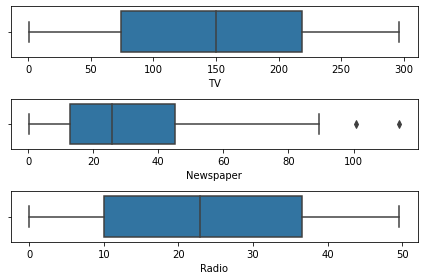

In [5]:
fig, axs = plt.subplots(3)
plt1 = sns.boxplot(x =advert['TV'], ax = axs[0])
plt2 = sns.boxplot(x = advert['Newspaper'],ax = axs[1])
plt3 = sns.boxplot(x= advert['Radio'], ax =axs[2])
plt.tight_layout()

There does not seem to be any outliers.

Next, I created a scatter plot for each mode of advertisement and sales to visualize the relationship between the two variables. From the scatter plots, it appeared that the relationship between the amount of money spent on advertisement and the corresponding sales may not exactly be linear. Therefore, I decided to try out different regression models, including simple linear regression, logarithmic regression, polynomial transformation (degree 2), and polynomial transformation (degree 3).

In [6]:
X = advert['TV'] #independent variable
y = advert['Sales'] #dependent variable

Text(0, 0.5, 'Sales of a product (in 1000s)')

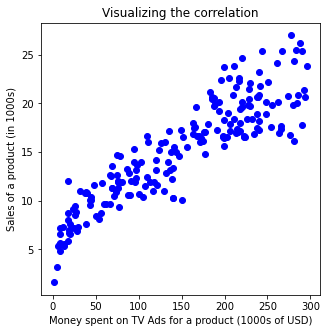

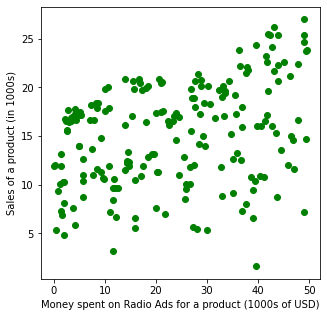

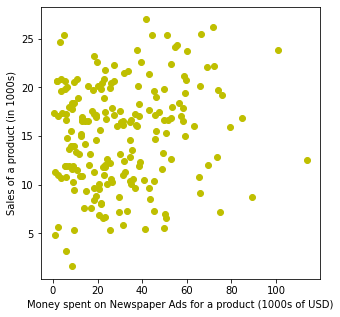

In [7]:
plt.figure(figsize=(5,5))
plt.scatter(X,y,color ='b')
plt.xlabel('Money spent on TV Ads for a product (1000s of USD)')
plt.ylabel('Sales of a product (in 1000s)')
plt.title('Visualizing the correlation')
plt.figure(figsize=(5,5))
plt.scatter(advert['Radio'],y,color ='g')
plt.xlabel('Money spent on Radio Ads for a product (1000s of USD)')
plt.ylabel('Sales of a product (in 1000s)')
plt.figure(figsize=(5,5))
plt.scatter(advert['Newspaper'],y,color ='y')
plt.xlabel('Money spent on Newspaper Ads for a product (1000s of USD)')
plt.ylabel('Sales of a product (in 1000s)')


From a quick look, it's visible how the money spent on TV ads is so much more correlated to the Sales of the product.

### d) Trying Models:

To determine the best model, I calculated the root mean squared error (RMSE) and mean absolute error (MAE) values for each model using the TV column. I found that the polynomial transformation model with degree 2 had the lowest RMSE and MAE. Therefore, I used this model to predict sales based on the amount of money spent on radio and newspaper advertising.

#### Simple Linear Regression:

In [8]:
ones = np.ones(len(X))
np.matrix(ones)

matrix([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1., 1., 1., 1., 1., 1., 1.]])

Combining the ones matrix and the TV ads column to be something like:

([[  1. , 230.1],
[  1. ,  44.5],
[  1. ,  17.2]
...
[  1. , 177. ],
[  1. , 283.6],
[  1. , 232.1]])

In [9]:
X = np.concatenate((ones.reshape(-1, 1), np.matrix(X).reshape(-1, 1)), axis=1)


In [10]:
y = np.matrix(y)
y = np.matrix(y.T)

Finding the least squares solution:

In [11]:
x=np.linalg.inv(X.T*X)*X.T*y

In [12]:
x

matrix([[6.97482149],
        [0.05546477]])

y-intercept: 6.97482149

Slope: 0.05546477

In [13]:
a = 6.97482149 # y-intercept
b = 0.05546477 # Slope

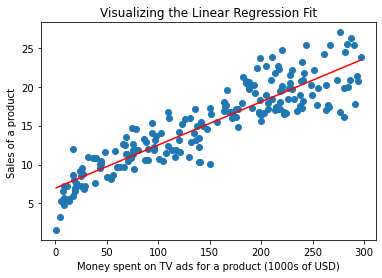

In [14]:
X2 = np.linspace(np.min(X[:,1]), np.max(X[:,1]),200)
y2 = a + b*X2
plt.scatter(advert['TV'], advert['Sales'])
plt.plot(X2, y2, 'r')
plt.xlabel('Money spent on TV ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Linear Regression Fit')
plt.savefig('LRTV')

In [15]:
score = (mean_squared_error(advert['Sales'], y2,squared = False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 7.18


In [16]:
score = (mean_absolute_error(advert['Sales'], y2))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 5.89


#### Logarithmic Transformation:

In [17]:
X_log = np.log(X)

In [18]:
y_log = y

In [19]:
X_log[:,0]=1


In [20]:
x_log=np.linalg.inv(X_log.T*X_log)*X_log.T*y_log

In [21]:
x_log

matrix([[-5.90743674],
        [ 4.50293333]])

In [22]:
a = -5.90743674 # y-intercept
b = 4.50293333 # Slope

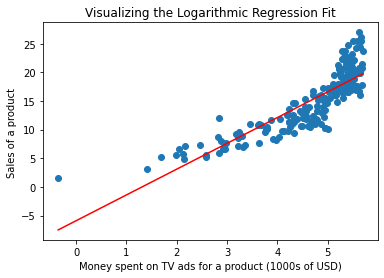

In [23]:
X2_log = np.linspace(np.min(X_log[:,1]), np.max(X_log[:,1]),200)

y2_log = a + b*X2_log

#Have to convert data to 1D in order to plot the scatterplot
plt.scatter(np.array(X_log[:,1].flatten()).flatten(), np.array(y_log.flatten()).flatten())
plt.plot(X2_log, y2_log, 'r')
plt.xlabel('Money spent on TV ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Logarithmic Regression Fit')
plt.savefig('LoRTV')

In [24]:
score = (mean_squared_error(np.array(y_log.flatten()).flatten(), y2_log, squared=False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 13.17


In [25]:
score = (mean_absolute_error(np.array(y_log.flatten()).flatten(), y2_log))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 10.72


#### Polynomial Transformation (Degree 2 and 3 respectively):

In [26]:
advert['Square'] = advert.apply(lambda row:row.TV**2,axis=1)

In [27]:
advert['Cube'] = advert.apply(lambda row:row.TV**3, axis=1)

In [28]:
advert.head()

,TV,Radio,Newspaper,Sales,Square,Cube
0,230.1,37.8,69.2,22.1,52946.01,1.218288e+07
1,44.5,39.3,45.1,10.4,1980.25,8.812112e+04
2,17.2,45.9,69.3,12.0,295.84,5.088448e+03
3,151.5,41.3,58.5,16.5,22952.25,3.477266e+06
4,180.8,10.8,58.4,17.9,32688.64,5.910106e+06


In [29]:
X_c = advert.drop(['Radio','Newspaper','Sales','Cube','TV'],axis=1)
Y_c = advert.iloc[:,3]


In [30]:
X_c = np.matrix(X_c)
Y_c = np.matrix(Y_c)

In [31]:
X_c = np.concatenate((ones.reshape(-1, 1), np.matrix(X_c).reshape(-1, 1)), axis=1)


In [32]:
x_log=np.linalg.inv(X_c.T*X_c)*X_c.T*Y_c.T

In [33]:
x_log

matrix([[1.00648900e+01],
        [1.74944101e-04]])

In [34]:
a = 1.00648900e+01 # y-intercept
b = 1.74944101e-04 # Slope

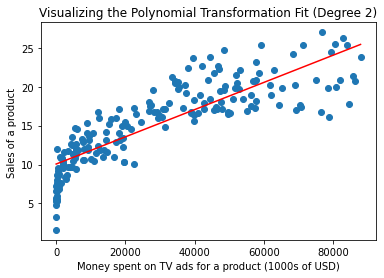

In [35]:
X2_log = np.linspace(np.min(X_c[:,1]), np.max(X_c[:,1]),200)

y2_log = a + b*X2_log

#Have to convert data to 1D in order to plot the scatterplot
plt.scatter(np.array(X_c[:,1].flatten()).flatten(), np.array(Y_c.flatten()).flatten())
plt.plot(X2_log, y2_log, 'r')
plt.xlabel('Money spent on TV ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Polynomial Transformation Fit (Degree 2)')
plt.savefig('Po2TV')

In [36]:
score = np.sqrt(mean_squared_error(np.array(Y_c.flatten()).flatten(), y2_log, squared=False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 2.73


In [37]:
score = (mean_absolute_error(np.array(Y_c.flatten()).flatten(), y2_log))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 6.07


In [38]:
X_c = advert.drop(['Radio','Newspaper','Sales','Square','TV'],axis=1)
Y_c = advert.iloc[:,3]


In [39]:
X_c = np.matrix(X_c)
Y_c = np.matrix(Y_c)

In [40]:
X_c = np.concatenate((ones.reshape(-1, 1), np.matrix(X_c).reshape(-1, 1)), axis=1)


In [41]:
x_log=np.linalg.inv(X_c.T*X_c)*X_c.T*Y_c.T

In [42]:
x_log

matrix([[1.14164096e+01],
        [5.82967672e-07]])

In [43]:
a = 1.14164096e+01 # y-intercept
b = 5.82967672e-07 # Slope

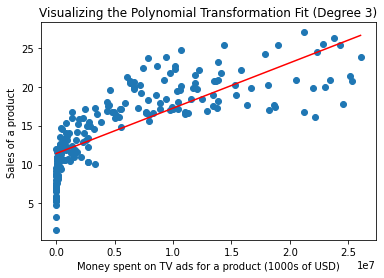

In [44]:
X2_log = np.linspace(np.min(X_c[:,1]), np.max(X_c[:,1]),200)

y2_log = a + b*X2_log

#Have to convert data to 1D in order to plot the scatterplot
plt.scatter(np.array(X_c[:,1].flatten()).flatten(), np.array(Y_c.flatten()).flatten())
plt.plot(X2_log, y2_log, 'r')
plt.xlabel('Money spent on TV ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Polynomial Transformation Fit (Degree 3)')
plt.savefig('Po3TV')

In [45]:
score = np.sqrt(mean_squared_error(np.array(Y_c.flatten()).flatten(), y2_log, squared=False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 2.82


In [46]:
score = (mean_absolute_error(np.array(Y_c.flatten()).flatten(), y2_log))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 6.46


#### Error Values for Different Fits:
- Simple Linear Regression: 
    - RMSE: 7.18
    - MAE: 5.89
- Logarithmic Transformation:
    - RMSE: 13.17
    - MAE: 10.72
- Polynomial Transformation (Degree 2):
    - RMSE: 2.73
    - MAE: 6.07
- Polynomial Transformation (Degree 3):
    - RMSE: 2.82
    - MAE: 6.46

#### So, it seems like Polynomial Transformation (Degree 2) ended up having the best fit with least errors

### e) Polynomial Transformation (Degree 2) Model on the Radio Column:

In [47]:
advert['SquareRadio'] = advert.apply(lambda row: row.Radio**2, axis =1 )


In [48]:
X_c = advert.drop(['Radio','Newspaper','Sales','Cube','TV', 'Square'],axis=1)
Y_c = advert.iloc[:,3]


In [49]:
X_c = np.matrix(X_c)
Y_c = np.matrix(Y_c)

In [50]:
X_c = np.concatenate((ones.reshape(-1, 1), np.matrix(X_c).reshape(-1, 1)), axis=1)


In [51]:
x_log=np.linalg.inv(X_c.T*X_c)*X_c.T*Y_c.T

In [52]:
x_log

matrix([[1.31989127e+01],
        [2.53976005e-03]])

In [53]:
a = 1.31989127e+01 # y-intercept
b = 2.53976005e-03 # Slope

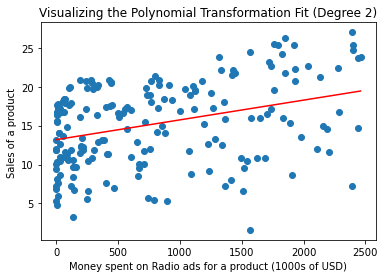

In [54]:
X2_log = np.linspace(np.min(X_c[:,1]), np.max(X_c[:,1]),200)

y2_log = a + b*X2_log

#Have to convert data to 1D in order to plot the scatterplot
plt.scatter(np.array(X_c[:,1].flatten()).flatten(), np.array(Y_c.flatten()).flatten())
plt.plot(X2_log, y2_log, 'r')
plt.xlabel('Money spent on Radio ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Polynomial Transformation Fit (Degree 2)')
plt.savefig('Po2R')

In [55]:
score = np.sqrt(mean_squared_error(np.array(Y_c.flatten()).flatten(), y2_log, squared=False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 2.39


In [56]:
score = (mean_absolute_error(np.array(Y_c.flatten()).flatten(), y2_log))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 4.68


### f) Polynomial Transformation (Degree 2) Model on the Newspaper Column:

In [57]:
advert['SquareNews'] = advert.apply(lambda row: row.Newspaper**2, axis =1 )


In [58]:
advert

,TV,Radio,Newspaper,Sales,Square,Cube,SquareRadio,SquareNews
0,230.1,37.8,69.2,22.1,52946.01,1.218288e+07,1428.84,4788.64
1,44.5,39.3,45.1,10.4,1980.25,8.812112e+04,1544.49,2034.01
2,17.2,45.9,69.3,12.0,295.84,5.088448e+03,2106.81,4802.49
3,151.5,41.3,58.5,16.5,22952.25,3.477266e+06,1705.69,3422.25
4,180.8,10.8,58.4,17.9,32688.64,5.910106e+06,116.64,3410.56
...,...,...,...,...,...,...,...,...
195,38.2,3.7,13.8,7.6,1459.24,5.574297e+04,13.69,190.44
196,94.2,4.9,8.1,14.0,8873.64,8.358969e+05,24.01,65.61
197,177.0,9.3,6.4,14.8,31329.00,5.545233e+06,86.49,40.96
198,283.6,42.0,66.2,25.5,80428.96,2.280965e+07,1764.00,4382.44


In [59]:
X_c = advert.drop(['Radio','Newspaper','Sales','Cube','TV', 'Square','SquareRadio'],axis=1)
Y_c = advert.iloc[:,3]


In [60]:
X_c = np.matrix(X_c)
Y_c = np.matrix(Y_c)

In [61]:
X_c = np.concatenate((ones.reshape(-1, 1), np.matrix(X_c).reshape(-1, 1)), axis=1)


In [62]:
x_log=np.linalg.inv(X_c.T*X_c)*X_c.T*Y_c.T

In [63]:
x_log

matrix([[1.45199062e+01],
        [4.34436806e-04]])

In [64]:
a = 1.45199062e+01 # y-intercept
b = 4.34436806e-04 # Slope

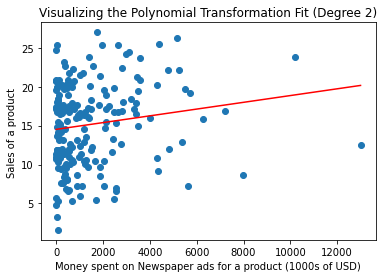

In [65]:
X2_log = np.linspace(np.min(X_c[:,1]), np.max(X_c[:,1]),200)

y2_log = a + b*X2_log

#Have to convert data to 1D in order to plot the scatterplot
plt.scatter(np.array(X_c[:,1].flatten()).flatten(), np.array(Y_c.flatten()).flatten())
plt.plot(X2_log, y2_log, 'r')
plt.xlabel('Money spent on Newspaper ads for a product (1000s of USD)')
plt.ylabel('Sales of a product ')
plt.title('Visualizing the Polynomial Transformation Fit (Degree 2)')
plt.savefig('Po2N')

In [66]:
score = np.sqrt(mean_squared_error(np.array(Y_c.flatten()).flatten(), y2_log, squared=False))
print("Root Mean Squared Error: {}".format(round(score, 2)))


Root Mean Squared Error: 2.44


In [67]:
score = (mean_absolute_error(np.array(Y_c.flatten()).flatten(), y2_log))
print("Mean Absolute Error: {}".format(round(score, 2)))


Mean Absolute Error: 4.86


## 3. Results:

Based on my analysis, I found that the polynomial transformation model with degree 2 was the most effective model for predicting sales based on the amount of money spent on advertisement. The RMSE value for this model was 2.73, and the MAE for this model was 6.07 which was the lowest amongst all models. 

When using this model to predict sales based on the amount of money spent on radio and newspaper advertising, I found that the model was able to predict sales with reasonable accuracy, but there were of course still some discrepancies between the predicted values and the actual values.

**Linear Regression Fit (Sales vs TV Ads)**

![Linear Regression Fit (Sales vs TV Ads)](LRTV.png)

**Logarithmic Transformation Fit (Sales vs TV Ads)**

![Logarithmic Transformation Fit (Sales vs TV Ads)](LoRTV.png)

**Polynomial Transformation (Degree 2) Fit (Sales vs TV Ads)**

![Polynomial Transformation (Degree 2) Fit (Sales vs TV Ads)](Po2TV.png)

**Polynomial Transformation (Degree 3) Fit (Sales vs TV Ads)**

![Polynomial Transformation (Degree 3) Fit (Sales vs TV Ads)](Po3TV.png)

**Since Polynomial Transformation (Degree 2) was the best fit, this is what the fit looked like when worked on the plot of Sales vs TV, Radio, and Newspaper respectively:**

Code Source: https://stackoverflow.com/questions/33647774/how-to-include-two-pictures-side-by-side-in-markdown-for-ipython-notebook-jupyt

<table><tr>
<td> <img src="Po2TV.png" alt="Polynommial (Deg2) Transformation on TV ads" style="width: 300px;"/> </td>
<td> <img src="Po2R.png" alt="Polynommial (Deg2) Transformation on Radio ads" style="width: 300px;"/> </td>
<td> <img src="Po2N.png" alt="Polynommial (Deg2) Transformation on Newspaper ads" style="width: 300px;"/> </td>
</tr></table>

## 4. Mathematical Analysis:

- Linear regression: This is a classical method from statistics that involves fitting a linear function to a set of data points by minimizing the sum of squared errors between the predicted and observed values. In my project, I used linear regression to model the relationship between TV ads and sales. Linear regression is based on the assumption that the relationship between the variables is linear, meaning that it can be expressed as a straight line. This assumption can be tested using diagnostic plots and other techniques.


- Least squares: The least squares method is a technique from linear algebra that is used to find the parameters of a linear regression model that minimize the sum of squared errors. The idea is to formulate the problem as a system of linear equations, where the unknowns are the coefficients of the linear function, and the data points are the knowns. The solution to the system can be obtained using matrix algebra, specifically the inverse of the  matrix (X) multiplied by the response variable (y). The resulting coefficients represent the best fit line that passes through the data points.


- Transormations: Furthermore, I used logarithmic and polynomial transformations to improve the performance of the linear regression model. I first applied the natural logarithm function to the TV ads column to transform it logarithmically, and then did the least squares fit on that. I then used a polynomial transformation of degree 2 and 3 by squaring and cubing respectively the TV ads column to capture non-linear relationships between the TV ads and sales. These transformations allowed me to fit a more accurate model to the data and improve the predictive power of the linear regression model.


- Matrix operations: To perform the least squares method, I used several matrix operations, such as transposition, multiplication, and inversion. Transposition is used to flip a matrix over its diagonal, effectively switching its rows and columns. Multiplication is used to combine matrices or vectors according to certain rules, such as the dot product. Inversion is used to find the inverse matrix of a square matrix, which is a matrix that, when multiplied by the original matrix, gives the identity matrix. In my project, I used the numpy library to perform these matrix operations efficiently.


- Evaluation metrics: To evaluate the performance of the linear regression model, I used two metrics: RMSE and MAE. RMSE stands for root mean squared error, and it measures the average distance between the predicted and observed values, taking into account the magnitude of the errors. MAE stands for mean absolute error, and it measures the average absolute difference between the predicted and observed values, ignoring the direction of the errors. These metrics are commonly used in regression analysis to assess the goodness of fit of the model and to compare different models.


$$RMSE = \sqrt {\frac{1}{N} \sum_{i=1}^{N} (x_{i} - \hat{x_{i}})^2}$$

$$MAE = {\frac{1}{N} \sum_{i=1}^{N} |{y_{i} - x_{i}}|}$$

## 5. Synthesis and Discussion:

Through this project, I learned that the relationship between the amount of money spent on advertisement and the corresponding sales may not be linear, and that different modes of advertisement may have different levels of effectiveness. I also learned that the polynomial transformation model with degree 2 was the most effective model for predicting sales based on the amount of money spent on advertisement.

One obstacle I ran into was trying to identify which dataset I should use and work with. While there are loads of datasets available on websites like Kaggle, I still had some trouble selecting this one. Additionally, the model I used may not be able to capture all of the complex relationships between the variables, and there may be other factors that contribute to the variation in sales that are not captured by the model. Nonetheless, my analysis provides a good starting point for understanding the relationship between advertisement spending and sales, and can be useful for businesses looking to optimize their advertising strategies.